In [1]:
import pandas as pd, numpy as np, time, pickle, joblib, warnings
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import loguniform, randint, uniform, mannwhitneyu, chi2_contingency
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from ucimlrepo import fetch_ucirepo

USE_CA = True          # True = Experiment A (13 predictors) | False = Experiment B (12 predictors, no ca)
TAG = "A_all13" if USE_CA else "B_noca"
out = lambda name: f"{TAG}_{name}"
SEED = 42

hd = fetch_ucirepo(id=45)                      # UCI Heart Disease (Cleveland)
X = hd.data.features.copy()
y = (hd.data.targets["num"] > 0).astype(int)   # 1 = disease

bin_cols = ["sex", "fbs", "exang"]
cat_cols = ["cp", "restecg", "slope", "thal"]
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"] + (["ca"] if USE_CA else [])
if not USE_CA:
    X = X.drop(columns=["ca"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)   # same split in A and B
Xtr, ytr = X_train.reset_index(drop=True), y_train.reset_index(drop=True)
yt = y_test.values

X_train.assign(target=y_train).to_csv(out("train.csv"), index=False)
X_test.assign(target=y_test).to_csv(out("test.csv"), index=False)
print(TAG, X.shape, X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(3).to_dict(), y_test.value_counts().to_dict())
print(X_train.isna().sum()[X_train.isna().sum() > 0].to_dict())

A_all13 (303, 13) (242, 13) (61, 13)
{0: 0.541, 1: 0.459} {0: 33, 1: 28}
{'ca': 1, 'thal': 1}


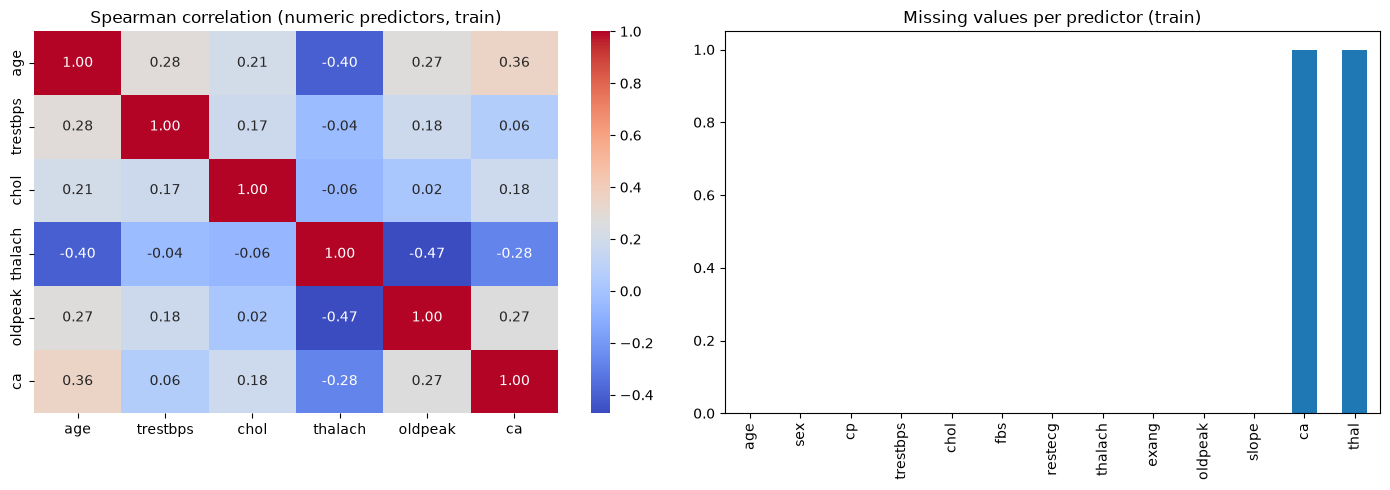

In [2]:
corr_cols = [c for c in ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"] if c in X_train.columns]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(X_train[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[0])
ax[0].set_title("Spearman correlation (numeric predictors, train)")
X_train.isna().sum().plot.bar(ax=ax[1]); ax[1].set_title("Missing values per predictor (train)")
plt.tight_layout(); plt.savefig(out("eda.png"), dpi=300); plt.show()

In [10]:
n0, n1 = (y_train == 0).sum(), (y_train == 1).sum()
fp = lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"
rows = []
for c in num_cols:
    a = X_train.loc[y_train == 0, c].dropna(); b = X_train.loc[y_train == 1, c].dropna()
    f = lambda s: f"{s.median():.1f} ({s.quantile(.25):.1f}-{s.quantile(.75):.1f})"
    rows.append([c, f(a), f(b), f"{X_train[c].isna().mean()*100:.1f}%", fp(mannwhitneyu(a, b).pvalue)])
for c in bin_cols + cat_cols:
    ct = pd.crosstab(X_train[c], y_train)        # counts table (yeh line zaroori hai)
    p = mc_chi2_p(X_train[c], y_train)           # Monte Carlo permutation p-value
    for i, lvl in enumerate(ct.index):
        rows.append([f"{c} = {lvl:g}", f"{ct.loc[lvl,0]} ({ct.loc[lvl,0]/n0*100:.1f}%)",
                     f"{ct.loc[lvl,1]} ({ct.loc[lvl,1]/n1*100:.1f}%)",
                     f"{X_train[c].isna().mean()*100:.1f}%" if i == 0 else "", fp(p) if i == 0 else ""])
table1 = pd.DataFrame(rows, columns=["Feature", f"No disease (n={n0})", f"Disease (n={n1})", "Missing", "p-value"])
table1.to_csv(out("table1.csv"), index=False); table1

,Feature,No disease (n=131),Disease (n=111),Missing,p-value
0,age,52.0 (45.0-59.0),58.0 (52.0-62.0),0.0%,<0.001
1,trestbps,129.0 (120.0-140.0),130.0 (120.0-145.0),0.0%,0.052
2,chol,240.0 (208.5-270.5),254.0 (224.0-283.5),0.0%,0.070
3,thalach,161.0 (148.5-172.0),142.0 (125.0-158.0),0.0%,<0.001
4,oldpeak,0.2 (0.0-1.1),1.2 (0.5-2.2),0.0%,<0.001
5,ca,0.0 (0.0-0.0),1.0 (0.0-2.0),0.4%,<0.001
6,sex = 0,59 (45.0%),18 (16.2%),0.0%,<0.001
7,sex = 1,72 (55.0%),93 (83.8%),,
8,fbs = 0,114 (87.0%),93 (83.8%),0.0%,0.585
9,fbs = 1,17 (13.0%),18 (16.2%),,


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score
from sklearn.base import clone
from xgboost import XGBClassifier

num_all = num_cols + bin_cols
def make_pre():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_all),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)])
def pipe(clf): return Pipeline([("pre", make_pre()), ("clf", clf)])

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
inner = StratifiedKFold(3, shuffle=True, random_state=SEED + 1)

spaces = {
 "LogReg": (LogisticRegression(max_iter=2000), {"clf__C": loguniform(1e-3, 1e2)}),
 "SVM":    (SVC(kernel="rbf", probability=True, random_state=SEED),
            {"clf__C": loguniform(1e-2, 1e2), "clf__gamma": loguniform(1e-4, 1)}),
 "RF":     (RandomForestClassifier(random_state=SEED, n_jobs=-1),
            {"clf__n_estimators": randint(100, 400), "clf__max_depth": [None, 3, 5, 8],
             "clf__min_samples_leaf": randint(1, 10)}),
 "XGBoost":(XGBClassifier(random_state=SEED, n_jobs=1, eval_metric="logloss"),
            {"clf__n_estimators": randint(100, 400), "clf__max_depth": randint(2, 6),
             "clf__learning_rate": loguniform(0.01, 0.3), "clf__subsample": uniform(0.6, 0.4)}),
 "MLP":    (MLPClassifier(max_iter=5000, random_state=SEED),      # max_iter raised from 1000
            {"clf__hidden_layer_sizes": [(16,), (32,), (32, 16)], "clf__alpha": loguniform(1e-5, 1e-1)}),
 "kNN":    (KNeighborsClassifier(),
            {"clf__n_neighbors": randint(3, 31), "clf__weights": ["uniform", "distance"]}),
}

def new_search(clf, grid):
    return RandomizedSearchCV(pipe(clf), grid, n_iter=15, cv=inner, scoring="roc_auc",
                              random_state=SEED, n_jobs=-1)

fold_scores = {n: [] for n in spaces}
oof = {n: np.zeros(len(ytr)) for n in spaces}      # genuinely nested out-of-fold probabilities
best_models, best_params = {}, {}

for name, (clf, grid) in spaces.items():
    t0 = time.time()
    for tr, va in cv.split(Xtr, ytr):
        s = new_search(clf, grid).fit(Xtr.iloc[tr], ytr.iloc[tr])   # tuning only on the outer-train part
        p = s.predict_proba(Xtr.iloc[va])[:, 1]
        oof[name][va] = p
        fold_scores[name].append(roc_auc_score(ytr.iloc[va], p))
    s = new_search(clf, grid).fit(Xtr, ytr)          # final tuning on the whole training set
    best_params[name] = s.best_params_
    best_models[name] = clone(s.best_estimator_)
    print(f"{name}: AUC {np.mean(fold_scores[name]):.3f} ± {np.std(fold_scores[name], ddof=1):.3f} ({time.time()-t0:.0f}s)")

# final fits + MLP convergence check
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    for m in best_models.values(): m.fit(Xtr, ytr)
mlp = best_models["MLP"].named_steps["clf"]
conv = not any(issubclass(x.category, ConvergenceWarning) for x in w)
print(f"MLP final model: n_iter_ = {mlp.n_iter_} (max {mlp.max_iter}), loss = {mlp.loss_:.4f}, converged = {conv}")

pd.DataFrame(fold_scores).round(3).to_csv(out("fold_scores.csv"), index=False)
pd.DataFrame(oof).to_csv(out("oof.csv"), index=False)
pd.Series(best_params).to_csv(out("best_params.csv"))
joblib.dump(best_models, out("best_models.pkl"))
pd.DataFrame(fold_scores).round(3)

LogReg: AUC 0.871 ± 0.042 (14s)


C:\ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=

SVM: AUC 0.871 ± 0.041 (7s)
RF: AUC 0.871 ± 0.038 (55s)
XGBoost: AUC 0.842 ± 0.048 (92s)
MLP: AUC 0.790 ± 0.026 (58s)
kNN: AUC 0.860 ± 0.050 (3s)
MLP final model: n_iter_ = 1622 (max 5000), loss = 0.1114, converged = True


,LogReg,SVM,RF,XGBoost,MLP,kNN
0,0.921,0.921,0.921,0.893,0.779,0.901
1,0.880,0.892,0.887,0.855,0.805,0.865
2,0.827,0.820,0.820,0.767,0.806,0.822
3,0.897,0.881,0.878,0.867,0.811,0.914
4,0.827,0.841,0.850,0.825,0.750,0.799


In [5]:
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, f1_score,
                             brier_score_loss, roc_curve, confusion_matrix)
thr = {}
for name in spaces:
    fpr, tpr, th = roc_curve(ytr, oof[name])
    thr[name] = th[np.where(tpr >= 0.80)[0][0]]
pd.Series(thr).to_csv(out("thresholds.csv"))
print("Thresholds:", {k: round(float(v), 3) for k, v in thr.items()})

probs = {n: m.predict_proba(X_test)[:, 1] for n, m in best_models.items()}

def metrics(y, p, t):
    pred = (p >= t).astype(int)
    tn, fp_, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(AUC=roc_auc_score(y, p), PR_AUC=average_precision_score(y, p),   # PR-AUC = average precision
                BalAcc=balanced_accuracy_score(y, pred), F1=f1_score(y, pred),
                Sens=tp/(tp+fn), Spec=tn/(tn+fp_),
                PPV=tp/(tp+fp_) if tp+fp_ else np.nan, NPV=tn/(tn+fn) if tn+fn else np.nan,
                Brier=brier_score_loss(y, p))

rng = np.random.default_rng(SEED)
idx = [rng.integers(0, len(yt), len(yt)) for _ in range(1000)]
idx = [i for i in idx if 0 < yt[i].sum() < len(i)]
boot = {n: pd.DataFrame([metrics(yt[i], p[i], thr[n]) for i in idx]) for n, p in probs.items()}

rows = []
for n, p in probs.items():
    pt = metrics(yt, p, thr[n]); lo, hi = boot[n].quantile(.025), boot[n].quantile(.975)
    rows.append({"Model": n, **{k: f"{pt[k]:.3f} ({lo[k]:.3f}-{hi[k]:.3f})" for k in pt}})
results = pd.DataFrame(rows).set_index("Model")
results.to_csv(out("results.csv")); results

Thresholds: {'LogReg': 0.439, 'SVM': 0.438, 'RF': 0.44, 'XGBoost': 0.357, 'MLP': 0.218, 'kNN': 0.4}


,AUC,PR_AUC,BalAcc,F1,Sens,Spec,PPV,NPV,Brier
Model,,,,,,,,,
LogReg,0.956 (0.904-0.991),0.947 (0.880-0.990),0.891 (0.812-0.963),0.885 (0.792-0.962),0.964 (0.880-1.000),0.818 (0.684-0.941),0.818 (0.687-0.941),0.964 (0.880-1.000),0.102 (0.073-0.132)
SVM,0.956 (0.904-0.990),0.950 (0.888-0.990),0.838 (0.739-0.926),0.828 (0.704-0.923),0.857 (0.704-0.967),0.818 (0.688-0.941),0.800 (0.655-0.933),0.871 (0.741-0.970),0.100 (0.067-0.134)
RF,0.931 (0.860-0.982),0.908 (0.806-0.982),0.861 (0.776-0.938),0.857 (0.759-0.943),0.964 (0.880-1.000),0.758 (0.607-0.906),0.771 (0.639-0.909),0.962 (0.870-1.000),0.121 (0.091-0.153)
XGBoost,0.903 (0.812-0.968),0.867 (0.747-0.967),0.846 (0.762-0.926),0.844 (0.741-0.928),0.964 (0.880-1.000),0.727 (0.571-0.875),0.750 (0.615-0.889),0.960 (0.864-1.000),0.127 (0.093-0.168)
MLP,0.906 (0.819-0.964),0.895 (0.793-0.964),0.831 (0.735-0.912),0.831 (0.721-0.919),0.964 (0.880-1.000),0.697 (0.531-0.853),0.730 (0.585-0.868),0.958 (0.857-1.000),0.143 (0.082-0.217)
kNN,0.957 (0.903-0.992),0.942 (0.871-0.992),0.894 (0.821-0.964),0.889 (0.800-0.967),1.000 (1.000-1.000),0.788 (0.643-0.929),0.800 (0.667-0.935),1.000 (1.000-1.000),0.104 (0.076-0.133)


In [6]:
def timeit(fn, reps=30, warm=2):
    for _ in range(warm): fn()
    ts = []
    for _ in range(reps):
        t = time.perf_counter(); fn(); ts.append(time.perf_counter() - t)
    return np.median(ts), np.percentile(ts, 25), np.percentile(ts, 75)

X1000 = pd.concat([X_test] * (1000 // len(X_test) + 1)).iloc[:1000]
train_med, rows = {}, []
for n, m in best_models.items():
    a = timeit(lambda m=m: clone(m).fit(Xtr, ytr))
    b = timeit(lambda m=m: m.predict_proba(X1000))
    train_med[n] = a[0]
    rows.append([n, f"{a[0]:.3f} ({a[1]:.3f}-{a[2]:.3f})", f"{b[0]:.4f} ({b[1]:.4f}-{b[2]:.4f})",
                 round(len(pickle.dumps(m)) / 1e6, 3)])
eff = pd.DataFrame(rows, columns=["Model", "Train time, median (IQR) s",
                                  "Inference per 1000, median (IQR) s", "Size (MB)"]).set_index("Model")
eff.to_csv(out("efficiency.csv")); eff

C:\ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=

,"Train time, median (IQR) s","Inference per 1000, median (IQR) s",Size (MB)
Model,,,
LogReg,0.020 (0.017-0.027),0.0057 (0.0055-0.0072),0.004
SVM,0.027 (0.025-0.029),0.0306 (0.0282-0.0346),0.030
RF,0.628 (0.524-0.725),0.0982 (0.0894-0.1011),0.652
XGBoost,0.756 (0.744-0.764),0.0159 (0.0139-0.0182),0.244
MLP,1.465 (1.423-1.503),0.0056 (0.0055-0.0066),0.053
kNN,0.014 (0.013-0.016),0.0164 (0.0141-0.0192),0.046


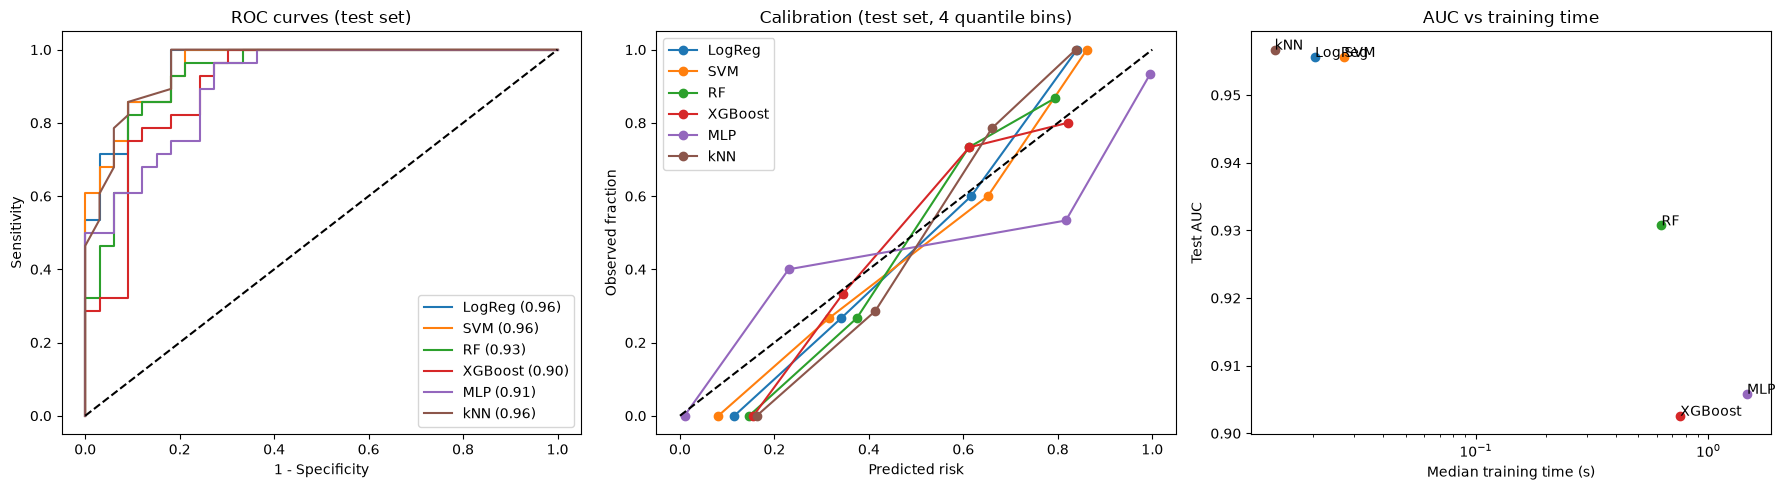

Calibration bin sizes (LogReg): [15 15 15 16]


In [7]:
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for n, p in probs.items():
    fpr, tpr, _ = roc_curve(yt, p)
    ax[0].plot(fpr, tpr, label=f"{n} ({roc_auc_score(yt, p):.2f})")
    fr, mp = calibration_curve(yt, p, n_bins=4, strategy="quantile")
    ax[1].plot(mp, fr, marker="o", label=n)
    ax[2].scatter(train_med[n], roc_auc_score(yt, p)); ax[2].annotate(n, (train_med[n], roc_auc_score(yt, p)))
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].legend()
ax[0].set(title="ROC curves (test set)", xlabel="1 - Specificity", ylabel="Sensitivity")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].legend()
ax[1].set(title="Calibration (test set, 4 quantile bins)", xlabel="Predicted risk", ylabel="Observed fraction")
ax[2].set(xscale="log", title="AUC vs training time", xlabel="Median training time (s)", ylabel="Test AUC")
plt.tight_layout(); plt.savefig(out("figures.png"), dpi=300); plt.show()
print("Calibration bin sizes (LogReg):", np.histogram(probs["LogReg"], bins=np.quantile(probs["LogReg"], [0, .25, .5, .75, 1]))[0])

In [8]:
%pip install scikit-posthocs statsmodels -q
import scikit_posthocs as sp
from scipy.stats import friedmanchisquare, norm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import mcnemar

fs = pd.DataFrame(fold_scores)       # exploratory: only 5 overlapping folds
print(friedmanchisquare(*[fs[c] for c in fs]))
nem = sp.posthoc_nemenyi_friedman(fs.values); nem.index = nem.columns = fs.columns
nem.round(3).to_csv(out("nemenyi.csv")); display(nem.round(3))

def _mid(x):
    J = np.argsort(x); Z = x[J]; N = len(x); T = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]: j += 1
        T[i:j] = 0.5 * (i + j - 1); i = j
    T2 = np.empty(N); T2[J] = T + 1
    return T2
def delong(y, p1, p2):
    o = (-y).argsort(); y = y[o]; m = int(y.sum()); n = len(y) - m
    P = np.vstack([p1[o], p2[o]])
    tz = np.array([_mid(P[r]) for r in range(2)])
    tx = np.array([_mid(P[r, :m]) for r in range(2)]); ty = np.array([_mid(P[r, m:]) for r in range(2)])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1) / (2 * n)
    S = np.cov((tz[:, :m] - tx) / n) / m + np.cov(1 - (tz[:, m:] - ty) / m) / n
    l = np.array([1, -1])
    return 2 * norm.sf(abs((aucs[0] - aucs[1]) / np.sqrt(l @ S @ l)))

others = [n for n in probs if n != "LogReg"]; pd_, pm = [], []
for n in others:
    pd_.append(delong(yt, probs["LogReg"], probs[n]))
    a = (probs["LogReg"] >= thr["LogReg"]).astype(int) == yt     # correct / incorrect per patient
    b = (probs[n] >= thr[n]).astype(int) == yt
    pm.append(mcnemar([[(a & b).sum(), (a & ~b).sum()], [(~a & b).sum(), (~a & ~b).sum()]], exact=True).pvalue)
tests = pd.DataFrame({"Model": others, "DeLong p": pd_, "DeLong p (Holm)": multipletests(pd_, method="holm")[1],
                      "McNemar p": pm, "McNemar p (Holm)": multipletests(pm, method="holm")[1]}).round(4)
tests.to_csv(out("tests.csv"), index=False); tests

Note: you may need to restart the kernel to use updated packages.
FriedmanchisquareResult(statistic=np.float64(17.16374269005848), pvalue=np.float64(0.00419949886612395))



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


,LogReg,SVM,RF,XGBoost,MLP,kNN
LogReg,1.000,1.000,1.000,0.168,0.028,0.959
SVM,1.000,1.000,1.000,0.239,0.047,0.985
RF,1.000,1.000,1.000,0.239,0.047,0.985
XGBoost,0.168,0.239,0.239,1.000,0.985,0.650
MLP,0.028,0.047,0.047,0.985,1.000,0.239
kNN,0.959,0.985,0.985,0.650,0.239,1.000


,Model,DeLong p,DeLong p (Holm),McNemar p,McNemar p (Holm)
0,SVM,1.0000,1.0000,0.3750,1.0
1,RF,0.1365,0.4094,0.6250,1.0
2,XGBoost,0.0164,0.0818,0.3750,1.0
3,MLP,0.0551,0.2204,0.2188,1.0
4,kNN,0.9122,1.0000,1.0000,1.0


C:\ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


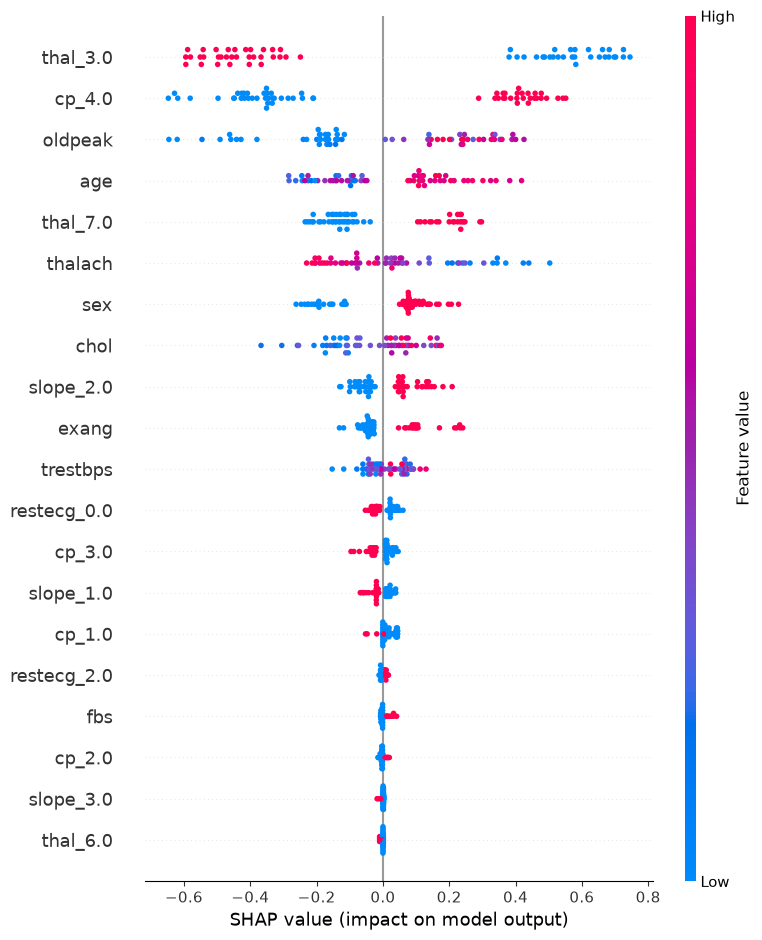

thal        0.630
cp          0.426
oldpeak     0.257
age         0.169
thalach     0.150
sex         0.128
chol        0.110
slope       0.097
exang       0.074
trestbps    0.049
restecg     0.036
fbs         0.006
dtype: float32

In [9]:
import shap
xgb = best_models["XGBoost"]; pre = xgb.named_steps["pre"]
names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
Xt = pd.DataFrame(pre.transform(X_test), columns=names)
sv = shap.TreeExplainer(xgb.named_steps["clf"]).shap_values(Xt)   # log-odds scale, tree-path-dependent
shap.summary_plot(sv, Xt, show=False); plt.savefig(out("shap.png"), dpi=300, bbox_inches="tight"); plt.show()

sv_df = pd.DataFrame(sv, columns=names)
grouped = sv_df.T.groupby(lambda s: s.split("_")[0]).sum().T      # one-hot levels summed per original predictor
imp = grouped.abs().mean().sort_values(ascending=False)
imp.to_csv(out("shap_importance.csv")); display(imp.round(3))

In [10]:
import sys, sklearn, xgboost, shap, scipy, scikit_posthocs, statsmodels
print("Python", sys.version.split()[0], "| sklearn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| shap", shap.__version__, "| scipy", scipy.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| posthocs", scikit_posthocs.__version__, "| statsmodels", statsmodels.__version__)

Python 3.13.14 | sklearn 1.9.1 | xgboost 3.4.1 | shap 0.54.1 | scipy 1.18.1 | numpy 2.5.4 | pandas 3.1.1 | posthocs 0.17.1 | statsmodels 0.15.0


In [11]:
A = pd.read_csv("A_all13_results.csv", index_col=0); B = pd.read_csv("B_noca_results.csv", index_col=0)
cmp = pd.DataFrame({"AUC with ca (A)": A["AUC"], "AUC without ca (B)": B["AUC"],
                    "Sens A": A["Sens"], "Sens B": B["Sens"], "Spec A": A["Spec"], "Spec B": B["Spec"]})
cmp.to_csv("A_vs_B.csv"); cmp

,AUC with ca (A),AUC without ca (B),Sens A,Sens B,Spec A,Spec B
Model,,,,,,
LogReg,0.963 (0.905-1.000),0.956 (0.904-0.991),0.929 (0.821-1.000),0.964 (0.880-1.000),0.818 (0.686-0.941),0.818 (0.684-0.941)
SVM,0.958 (0.899-0.996),0.956 (0.904-0.990),0.929 (0.821-1.000),0.857 (0.704-0.967),0.788 (0.639-0.923),0.818 (0.688-0.941)
RF,0.957 (0.898-0.995),0.931 (0.860-0.982),0.929 (0.821-1.000),0.964 (0.880-1.000),0.848 (0.722-0.963),0.758 (0.607-0.906)
XGBoost,0.957 (0.899-0.995),0.903 (0.812-0.968),0.964 (0.880-1.000),0.964 (0.880-1.000),0.818 (0.686-0.938),0.727 (0.571-0.875)
MLP,0.910 (0.823-0.971),0.906 (0.819-0.964),0.893 (0.760-1.000),0.964 (0.880-1.000),0.697 (0.545-0.850),0.697 (0.531-0.853)
kNN,0.961 (0.907-0.996),0.957 (0.903-0.992),0.929 (0.821-1.000),1.000 (1.000-1.000),0.788 (0.639-0.923),0.788 (0.643-0.929)
